In [1]:

# ==========================================
# Cell 1: Import Libraries & Configuration
# ==========================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, Birch
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Configuration
FILE_PATH = "5m Sales Records.csv"
SAMPLE_SIZE = 100000
RANDOM_STATE = 42

print("Libraries imported successfully!")
print("Dataset:", FILE_PATH)
print("Sample Size:", SAMPLE_SIZE)


Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!
Dataset: 5m Sales Records.csv
Sample Size: 100000


In [2]:

# ==========================================
# Cell 2: Data Loading & Preprocessing
# ==========================================

# 1. Load Dataset
data = pd.read_csv(
    FILE_PATH,
    nrows=SAMPLE_SIZE
)

print("Original Shape:", data.shape)

# 2. Convert Dates
data["Order Date"] = pd.to_datetime(
    data["Order Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

data["Ship Date"] = pd.to_datetime(
    data["Ship Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

# 3. Feature Engineering
data["Shipping Days"] = (
    data["Ship Date"] - data["Order Date"]
).dt.days

# 4. Feature Selection
features = [
    "Units Sold",
    "Shipping Days"
]

X = data[features].copy()

# 5. Data Quality Check
print("\n===== DATA QUALITY =====")
print("Missing Values:")
print(X.isnull().sum())

print("Invalid Units Sold:",
      (X["Units Sold"] <= 0).sum())

print("Invalid Shipping Days:",
      (X["Shipping Days"] < 0).sum())

# 6. Remove Invalid Records
X = X.dropna()

X = X[
    (X["Units Sold"] > 0) &
    (X["Shipping Days"] >= 0)
].copy()

print("\nCleaned Shape:", X.shape)

# 7. Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 8. Display Results
print("\n===== BEFORE SCALING =====")
display(X.describe().round(3))

print("\n===== AFTER SCALING =====")
scaled_df = pd.DataFrame(
    X_scaled,
    columns=features
)
display(scaled_df.describe().round(3))

print("\nPreprocessing Completed!")


Original Shape: (100000, 14)

===== DATA QUALITY =====
Missing Values:
Units Sold       0
Shipping Days    0
dtype: int64
Invalid Units Sold: 0
Invalid Shipping Days: 0

Cleaned Shape: (100000, 2)

===== BEFORE SCALING =====


,Units Sold,Shipping Days
count,100000.000,100000.000
mean,4987.503,25.035
std,2883.413,14.719
min,1.000,0.000
25%,2496.000,12.000
50%,4974.000,25.000
75%,7478.000,38.000
max,10000.000,50.000



===== AFTER SCALING =====


,Units Sold,Shipping Days
count,100000.000,100000.000
mean,-0.000,-0.000
std,1.000,1.000
min,-1.729,-1.701
25%,-0.864,-0.886
50%,-0.005,-0.002
75%,0.864,0.881
max,1.738,1.696



Preprocessing Completed!


In [3]:

# ==========================================
# Cell 3: K-Means Clustering
# ==========================================

# 1. Model Configuration
K = 4

kmeans = KMeans(
    n_clusters=K,
    random_state=RANDOM_STATE,
    n_init=10
)

# 2. Train Model
print("Training K-Means...")

start_time = time.perf_counter()

kmeans_labels = kmeans.fit_predict(X_scaled)

kmeans_time = time.perf_counter() - start_time

# 3. Model Results
print("\n===== K-MEANS RESULTS =====")
print("Number of Clusters:", len(np.unique(kmeans_labels)))
print("Execution Time:", round(kmeans_time, 4), "seconds")
print("Inertia:", round(kmeans.inertia_, 4))

# 4. Cluster Distribution
kmeans_results = X.copy()
kmeans_results["Cluster"] = kmeans_labels

print("\n===== CLUSTER DISTRIBUTION =====")
display(
    kmeans_results["Cluster"]
    .value_counts()
    .sort_index()
)

# 5. Cluster Characteristics
print("\n===== CLUSTER PROFILES =====")
display(
    kmeans_results.groupby("Cluster")[features]
    .mean()
    .round(2)
)

print("\nK-Means Completed!")


Training K-Means...

===== K-MEANS RESULTS =====
Number of Clusters: 4
Execution Time: 0.1577 seconds
Inertia: 49876.7123

===== CLUSTER DISTRIBUTION =====


Cluster
0    24726
1    24349
2    25455
3    25470
Name: count, dtype: int64


===== CLUSTER PROFILES =====


,Units Sold,Shipping Days
Cluster,,
0,2490.99,38.07
1,7496.50,11.92
2,2508.41,12.52
3,7490.16,37.42



K-Means Completed!


In [4]:

# ==========================================
# Cell 4: BIRCH Clustering
# ==========================================

# 1. Model Configuration
birch = Birch(
    n_clusters=K,
    threshold=0.5,
    branching_factor=50
)

# 2. Train Model
print("Training BIRCH...")

start_time = time.perf_counter()

birch_labels = birch.fit_predict(X_scaled)

birch_time = time.perf_counter() - start_time

# 3. Model Results
print("\n===== BIRCH RESULTS =====")
print("Number of Clusters:", len(np.unique(birch_labels)))
print("Execution Time:", round(birch_time, 4), "seconds")
print("Subclusters:", len(birch.subcluster_centers_))

# 4. Cluster Distribution
birch_results = X.copy()
birch_results["Cluster"] = birch_labels

print("\n===== CLUSTER DISTRIBUTION =====")
display(
    birch_results["Cluster"]
    .value_counts()
    .sort_index()
)

# 5. Cluster Characteristics
print("\n===== CLUSTER PROFILES =====")
display(
    birch_results.groupby("Cluster")[features]
    .mean()
    .round(2)
)

print("\nBIRCH Completed!")


Training BIRCH...

===== BIRCH RESULTS =====
Number of Clusters: 4
Execution Time: 0.8576 seconds
Subclusters: 12

===== CLUSTER DISTRIBUTION =====


Cluster
0    31974
1    25904
2    24894
3    17228
Name: count, dtype: int64


===== CLUSTER PROFILES =====


,Units Sold,Shipping Days
Cluster,,
0,6802.83,31.93
1,2699.88,10.88
2,2835.57,40.19
3,8167.52,11.63



BIRCH Completed!


In [5]:

# ==========================================
# Cell 5: Algorithm Evaluation
# ==========================================

# 1. Fixed evaluation sample
rng = np.random.default_rng(RANDOM_STATE)

eval_idx = rng.choice(
    len(X_scaled),
    size=2000,
    replace=False
)

eval_X = X_scaled[eval_idx]

# 2. Evaluation function
def evaluate_model(name, labels, execution_time):

    eval_labels = labels[eval_idx]

    if not np.isfinite(eval_X).all():
        raise ValueError("Invalid evaluation features")

    if not 1 < len(np.unique(eval_labels)) < len(eval_labels):
        raise ValueError("Invalid number of clusters")

    return {
        "Algorithm": name,
        "Silhouette Score": silhouette_score(
            eval_X, eval_labels
        ),
        "Davies-Bouldin Index": davies_bouldin_score(
            eval_X, eval_labels
        ),
        "Calinski-Harabasz Index": calinski_harabasz_score(
            eval_X, eval_labels
        ),
        "Execution Time (s)": execution_time
    }

# 3. Compare Algorithms
results = [
    evaluate_model(
        "K-Means",
        kmeans_labels,
        kmeans_time
    ),
    evaluate_model(
        "BIRCH",
        birch_labels,
        birch_time
    )
]

results_df = pd.DataFrame(results)

# 4. Display Results
print("===== ALGORITHM COMPARISON =====")

display(results_df.round(4))


===== ALGORITHM COMPARISON =====


,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Execution Time (s)
0,K-Means,0.4153,0.7539,2071.4086,0.1577
1,BIRCH,0.3472,0.9238,1479.0772,0.8576


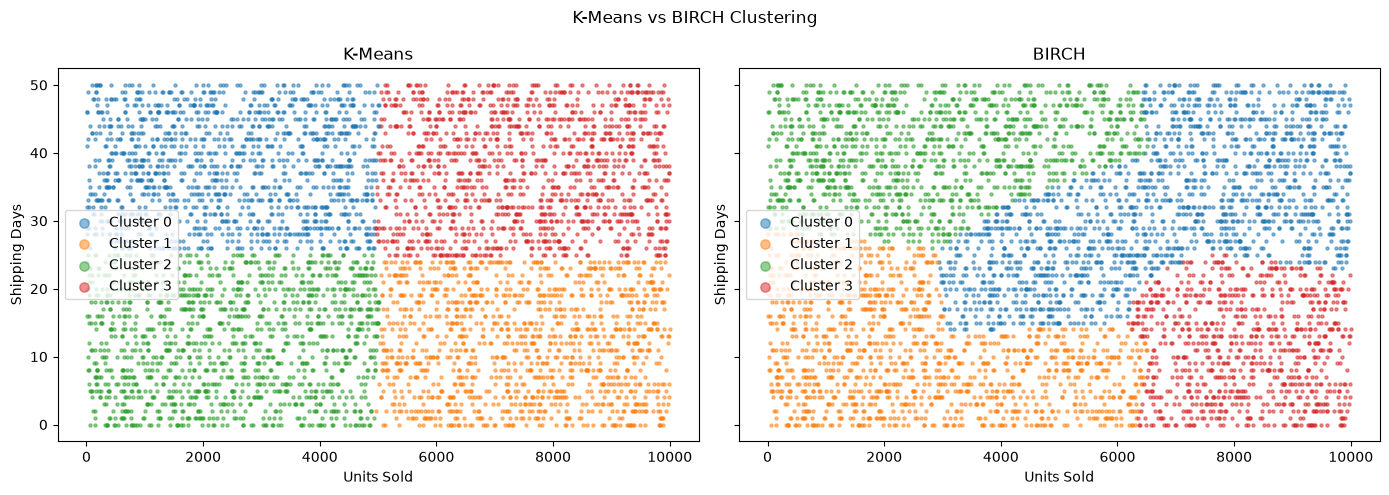

Visualization and export completed!
Results saved in: /Users/ntech/Desktop/ITCS544_Data Mining and Data Warehousing/DWH-GROUP/ITCS544-Sales-Analytics-DW/database/04_data_mining/results


In [6]:

# ==========================================
# Cell 6: Visualization & Export Results
# ==========================================

from pathlib import Path

# 1. Create output folder
output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

# 2. Sample the same records for both plots
rng = np.random.default_rng(RANDOM_STATE)

plot_idx = rng.choice(
    len(X),
    size=min(5000, len(X)),
    replace=False
)

plot_data = X.iloc[plot_idx]

# 3. Visualize Clusters
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharex=True,
    sharey=True
)

algorithms = [
    ("K-Means", kmeans_labels),
    ("BIRCH", birch_labels)
]

for ax, (name, labels) in zip(axes, algorithms):

    plot_labels = labels[plot_idx]

    for cluster in np.unique(plot_labels):
        mask = plot_labels == cluster

        ax.scatter(
            plot_data.loc[mask, "Units Sold"],
            plot_data.loc[mask, "Shipping Days"],
            s=5,
            alpha=0.5,
            label=f"Cluster {cluster}"
        )

    ax.set_title(name)
    ax.set_xlabel("Units Sold")
    ax.set_ylabel("Shipping Days")
    ax.legend(markerscale=3)

plt.suptitle("K-Means vs BIRCH Clustering")
plt.tight_layout()

plt.savefig(
    output_dir / "cluster_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 4. Export comparison results
results_df.to_csv(
    output_dir / "algorithm_comparison.csv",
    index=False
)

# 5. Export cluster profiles
kmeans_results.groupby("Cluster")[features].agg(
    ["count", "mean"]
).to_csv(output_dir / "kmeans_profiles.csv")

birch_results.groupby("Cluster")[features].agg(
    ["count", "mean"]
).to_csv(output_dir / "birch_profiles.csv")

print("Visualization and export completed!")
print("Results saved in:", output_dir.resolve())


In [8]:

# ==========================================
# Cell 7: Hyperparameter Tuning
# ==========================================

# 1. Parameter Settings
k_values = [3, 4, 5]
threshold_values = [0.3, 0.5, 0.7]

# Fixed evaluation sample
rng = np.random.default_rng(RANDOM_STATE)

eval_idx = rng.choice(
    len(X_scaled),
    size=2000,
    replace=False
)

eval_X = X_scaled[eval_idx]

tuning_results = []

# ==========================================
# 2. Evaluation Function
# ==========================================

def tune_and_evaluate(name, model, k, threshold=None):

    start = time.perf_counter()
    labels = model.fit_predict(X_scaled)
    elapsed = time.perf_counter() - start

    eval_labels = labels[eval_idx]
    n_clusters = len(np.unique(labels))

    if 1 < len(np.unique(eval_labels)) < len(eval_labels):
        silhouette = silhouette_score(eval_X, eval_labels)
        dbi = davies_bouldin_score(eval_X, eval_labels)
    else:
        silhouette = np.nan
        dbi = np.nan

    return {
        "Algorithm": name,
        "K": k,
        "Threshold": threshold,
        "Actual Clusters": n_clusters,
        "Silhouette": silhouette,
        "Davies-Bouldin": dbi,
        "Time (s)": elapsed
    }

# ==========================================
# 3. K-Means Tuning
# ==========================================

print("===== K-MEANS TUNING =====")

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )

    result = tune_and_evaluate(
        "K-Means", model, k
    )

    tuning_results.append(result)
    print(f"K-Means K={k} completed")

# ==========================================
# 4. BIRCH Tuning
# ==========================================

print("\n===== BIRCH TUNING =====")

for k in k_values:
    for threshold in threshold_values:

        model = Birch(
            n_clusters=k,
            threshold=threshold,
            branching_factor=50
        )

        result = tune_and_evaluate(
            "BIRCH", model, k, threshold
        )

        tuning_results.append(result)

        print(
            f"BIRCH K={k}, "
            f"Threshold={threshold} completed"
        )

# ==========================================
# 5. Display Results
# ==========================================

tuning_df = pd.DataFrame(tuning_results)

print("\n===== ALL TUNING RESULTS =====")
display(tuning_df.round(4))

print("\n===== BEST RESULT PER ALGORITHM =====")

best_results = (
    tuning_df.dropna(subset=["Silhouette"])
    .sort_values("Silhouette", ascending=False)
    .groupby("Algorithm", as_index=False)
    .first()
)

display(best_results.round(4))

print("\nHyperparameter Tuning Completed!")


===== K-MEANS TUNING =====
K-Means K=3 completed
K-Means K=4 completed
K-Means K=5 completed

===== BIRCH TUNING =====
BIRCH K=3, Threshold=0.3 completed
BIRCH K=3, Threshold=0.5 completed
BIRCH K=3, Threshold=0.7 completed
BIRCH K=4, Threshold=0.3 completed
BIRCH K=4, Threshold=0.5 completed
BIRCH K=4, Threshold=0.7 completed
BIRCH K=5, Threshold=0.3 completed
BIRCH K=5, Threshold=0.5 completed
BIRCH K=5, Threshold=0.7 completed

===== ALL TUNING RESULTS =====


,Algorithm,K,Threshold,Actual Clusters,Silhouette,Davies-Bouldin,Time (s)
0,K-Means,3,NaN,3,0.3836,0.8539,0.0896
1,K-Means,4,NaN,4,0.4153,0.7539,0.0893
2,K-Means,5,NaN,5,0.3946,0.8415,0.1274
3,BIRCH,3,0.3,3,0.3399,0.8985,0.3272
4,BIRCH,3,0.5,3,0.3332,0.9261,0.3262
5,BIRCH,3,0.7,3,0.3622,0.8602,0.3126
6,BIRCH,4,0.3,4,0.3671,0.8325,0.3366
7,BIRCH,4,0.5,4,0.3472,0.9238,0.3045
8,BIRCH,4,0.7,4,0.3761,0.7707,0.3044
9,BIRCH,5,0.3,5,0.3408,0.9576,0.3149



===== BEST RESULT PER ALGORITHM =====


,Algorithm,K,Threshold,Actual Clusters,Silhouette,Davies-Bouldin,Time (s)
0,BIRCH,4,0.7,4,0.3761,0.7707,0.3044
1,K-Means,4,NaN,4,0.4153,0.7539,0.0893



Hyperparameter Tuning Completed!


10,000 records - Run 1 completed
10,000 records - Run 2 completed
10,000 records - Run 3 completed
50,000 records - Run 1 completed
50,000 records - Run 2 completed
50,000 records - Run 3 completed
100,000 records - Run 1 completed
100,000 records - Run 2 completed
100,000 records - Run 3 completed

===== SCALABILITY RESULTS =====


,Records,Algorithm,Mean_Time,Std_Time,Min_Time,Max_Time
0,10000,BIRCH,0.0316,0.0003,0.0313,0.0318
1,10000,K-Means,0.0372,0.0031,0.0347,0.0407
2,50000,BIRCH,0.1583,0.0031,0.1551,0.1612
3,50000,K-Means,0.0564,0.0005,0.0559,0.0569
4,100000,BIRCH,0.3062,0.0012,0.3055,0.3075
5,100000,K-Means,0.0892,0.0052,0.0858,0.0953


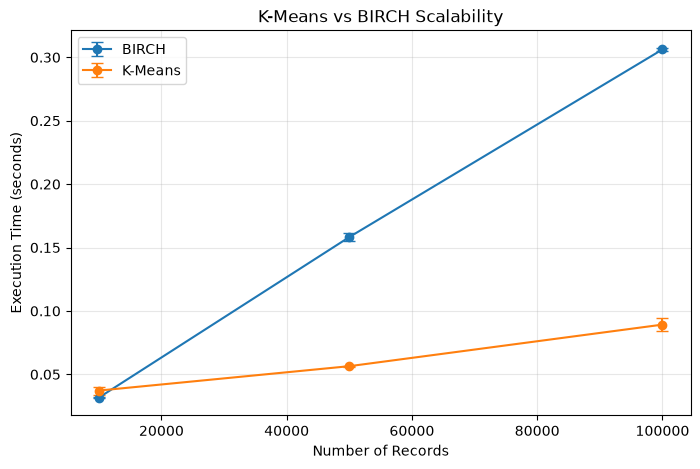


Scalability Benchmark Completed!


In [9]:

# ==========================================
# Cell 8: Scalability & Repeated Benchmark
# ==========================================

dataset_sizes = [10000, 50000, 100000]
repetitions = 3

benchmark_results = []

for size in dataset_sizes:

    X_test = X_scaled[:size]

    for run in range(1, repetitions + 1):

        models = {
            "K-Means": KMeans(
                n_clusters=4,
                random_state=RANDOM_STATE,
                n_init=10
            ),
            "BIRCH": Birch(
                n_clusters=4,
                threshold=0.7,
                branching_factor=50
            )
        }

        for name, model in models.items():

            start = time.perf_counter()

            labels = model.fit_predict(X_test)

            elapsed = time.perf_counter() - start

            benchmark_results.append({
                "Algorithm": name,
                "Records": size,
                "Run": run,
                "Time (s)": elapsed,
                "Clusters": len(np.unique(labels))
            })

        print(f"{size:,} records - Run {run} completed")

# ==========================================
# Summarize Results
# ==========================================

benchmark_df = pd.DataFrame(benchmark_results)

summary_df = benchmark_df.groupby(
    ["Records", "Algorithm"],
    as_index=False
).agg(
    Mean_Time=("Time (s)", "mean"),
    Std_Time=("Time (s)", "std"),
    Min_Time=("Time (s)", "min"),
    Max_Time=("Time (s)", "max")
)

print("\n===== SCALABILITY RESULTS =====")
display(summary_df.round(4))

# ==========================================
# Visualization
# ==========================================

plt.figure(figsize=(8, 5))

for name, group in summary_df.groupby("Algorithm"):
    plt.errorbar(
        group["Records"],
        group["Mean_Time"],
        yerr=group["Std_Time"],
        marker="o",
        capsize=4,
        label=name
    )

plt.xlabel("Number of Records")
plt.ylabel("Execution Time (seconds)")
plt.title("K-Means vs BIRCH Scalability")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    output_dir / "scalability_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

summary_df.to_csv(
    output_dir / "scalability_results.csv",
    index=False
)

print("\nScalability Benchmark Completed!")



Training final K-Means...

===== K-Means CLUSTER PROFILES =====


,Transactions,Avg_Units,Avg_Shipping_Days,Avg_Revenue,Avg_Profit,Online_Ratio,Segment
Cluster,,,,,,,
0,24726,2490.99,38.07,660728.41,194344.70,0.5,Low Volume / Slow Shipping
1,24349,7496.50,11.92,2006325.51,592509.46,0.5,High Volume / Fast Shipping
2,25455,2508.41,12.52,666135.95,196862.66,0.5,Low Volume / Fast Shipping
3,25470,7490.16,37.42,1987880.41,586652.03,0.5,High Volume / Slow Shipping



Training final BIRCH...

===== BIRCH CLUSTER PROFILES =====


,Transactions,Avg_Units,Avg_Shipping_Days,Avg_Revenue,Avg_Profit,Online_Ratio,Segment
Cluster,,,,,,,
0,33870,6670.22,13.63,1782051.63,525911.29,0.5,High Volume / Fast Shipping
1,30285,2505.42,36.40,665162.12,195865.01,0.5,Low Volume / Slow Shipping
2,21759,7804.80,37.77,2069307.41,611269.41,0.5,High Volume / Slow Shipping
3,14086,1925.95,8.36,514582.69,151962.81,0.5,Low Volume / Fast Shipping


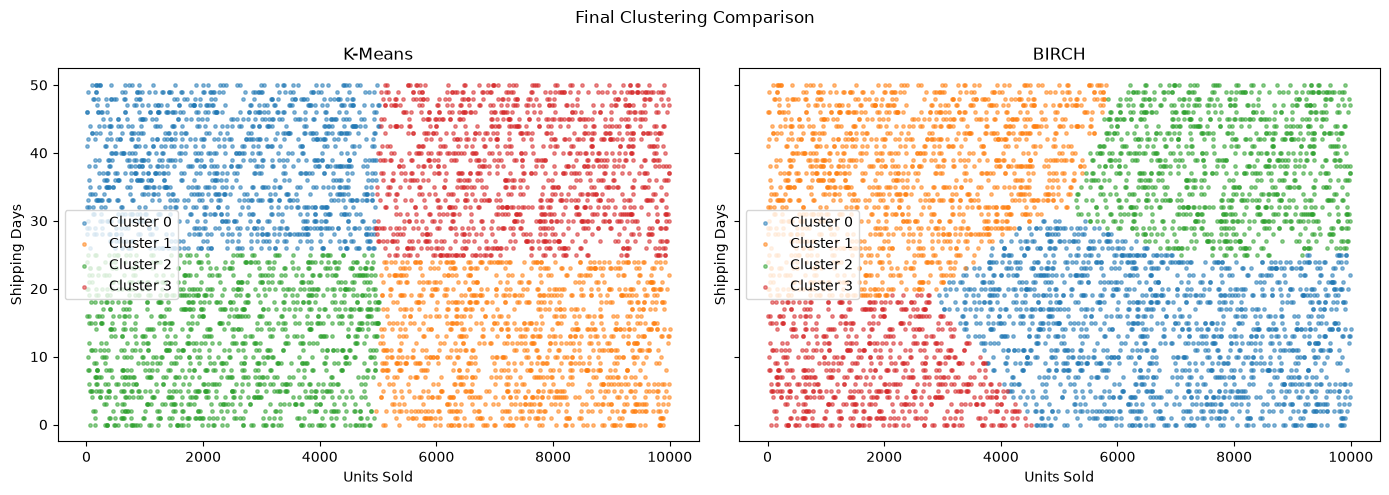


Final Clustering Completed!
Results saved to: /Users/ntech/Desktop/ITCS544_Data Mining and Data Warehousing/DWH-GROUP/ITCS544-Sales-Analytics-DW/database/04_data_mining/results


In [10]:

# ==========================================
# Cell 9: Final Model & Business Interpretation
# ==========================================

from pathlib import Path

output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

# ==========================================
# 1. Train Final Models
# ==========================================

final_models = {
    "K-Means": KMeans(
        n_clusters=4,
        random_state=RANDOM_STATE,
        n_init=10
    ),
    "BIRCH": Birch(
        n_clusters=4,
        threshold=0.7,
        branching_factor=50
    )
}

final_labels = {}
final_profiles = {}

# ==========================================
# 2. Cluster Profiling
# ==========================================

for name, model in final_models.items():

    print(f"\nTraining final {name}...")

    labels = model.fit_predict(X_scaled)
    final_labels[name] = labels

    # Align records with the cleaned dataset
    result = data.loc[X.index].copy()
    result["Cluster"] = labels

    result["Is_Online"] = (
        result["Sales Channel"] == "Online"
    ).astype(int)

    profile = result.groupby("Cluster").agg(
        Transactions=("Order ID", "count"),
        Avg_Units=("Units Sold", "mean"),
        Avg_Shipping_Days=("Shipping Days", "mean"),
        Avg_Revenue=("Total Revenue", "mean"),
        Avg_Profit=("Total Profit", "mean"),
        Online_Ratio=("Is_Online", "mean")
    )

    # Describe clusters based on their profiles
    median_units = X["Units Sold"].median()
    median_shipping = X["Shipping Days"].median()

    def describe_cluster(row):
        volume = (
            "High Volume"
            if row["Avg_Units"] >= median_units
            else "Low Volume"
        )

        shipping = (
            "Fast Shipping"
            if row["Avg_Shipping_Days"] < median_shipping
            else "Slow Shipping"
        )

        return f"{volume} / {shipping}"

    profile["Segment"] = profile.apply(
        describe_cluster,
        axis=1
    )

    final_profiles[name] = profile

    print(f"\n===== {name} CLUSTER PROFILES =====")
    display(profile.round(2))

    filename = name.lower().replace("-", "") + "_final.csv"
    profile.to_csv(output_dir / filename)

# ==========================================
# 3. Final Cluster Visualization
# ==========================================

rng = np.random.default_rng(RANDOM_STATE)

plot_idx = rng.choice(
    len(X),
    size=min(5000, len(X)),
    replace=False
)

plot_data = X.iloc[plot_idx]

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharex=True,
    sharey=True
)

for ax, (name, labels) in zip(
    axes,
    final_labels.items()
):

    plot_labels = labels[plot_idx]

    for cluster in np.unique(plot_labels):

        mask = plot_labels == cluster

        ax.scatter(
            plot_data.iloc[mask]["Units Sold"],
            plot_data.iloc[mask]["Shipping Days"],
            s=6,
            alpha=0.5,
            label=f"Cluster {cluster}"
        )

    ax.set_title(name)
    ax.set_xlabel("Units Sold")
    ax.set_ylabel("Shipping Days")
    ax.legend()

plt.suptitle("Final Clustering Comparison")
plt.tight_layout()

plt.savefig(
    output_dir / "final_clustering.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nFinal Clustering Completed!")
print("Results saved to:", output_dir.resolve())
